# Cinemática directa · de ángulos a posición

[Explicación completa y diagramas](README.md) · [Mapa de estudio](../README.md)

Notebook autocontenido: se ejecuta de arriba hacia abajo y no importa funciones de `code/`. Las ecuaciones se implementan aquí para poder leerlas. Las salidas guardadas muestran simulación del modelo rígido nominal; no son mediciones del prototipo.

**Convenciones:** base fija, metros, radianes y vectores columna. Las longitudes se toman de la tabla 2 de Ramzy et al. (2024); los métodos siguen las semanas 4–9 del curso. [Fuentes y alcance](../../docs/paper.md).

## 1. Qué se calcula

La entrada es $q=(q_1,q_2,q_3)$: giro de base, hombro y codo. La salida $p=(x,y,z)$ es la posición del efector. Se comienza con un ejemplo elegido para estudiar el modelo, no con una medición del paper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
l1, l2, l3 = 0.04, 0.29, 0.24  # metros, tabla 2 del paper

q = np.deg2rad([30, 40, -50])
print("Ángulos (rad):", q)

Ángulos (rad): [ 0.523599  0.698132 -0.872665]


## 2. Proyectar los eslabones

El segundo eslabón móvil forma el ángulo $q_2+q_3$ respecto de la horizontal. Su ángulo no es solamente $q_3$, porque el hombro ya ha girado.

$$\rho=l_2\cos q_2+l_3\cos(q_2+q_3),\quad h=l_2\sin q_2+l_3\sin(q_2+q_3).$$
$$p=[\rho\cos q_1,\rho\sin q_1,l_1+h]^T.$$

`rho` es una coordenada radial con signo. `height` es altura respecto del hombro. La altura fija `l1` se suma al final.

In [2]:
def position(q):
    q1, q2, q3 = q
    rho = l2 * np.cos(q2) + l3 * np.cos(q2 + q3)
    height = l2 * np.sin(q2) + l3 * np.sin(q2 + q3)
    return np.array([np.cos(q1) * rho, np.sin(q1) * rho, l1 + height])

p = position(q)
print("Posición (m):", p)

Posición (m): [0.397078 0.229253 0.184733]


## 3. Incorporar orientación con DH

Una transformación homogénea $M=\begin{bmatrix}R&p\\0&1\end{bmatrix}$ transporta coordenadas entre marcos. `R` tiene forma 3×3 y `p`, 3×1. DH estándar aplica $R_z(\theta)T_z(d)T_x(a)R_x(\alpha)$.

El orden de argumentos sigue la clase: `theta, d, a, alpha`. `@` multiplica matrices; `*` multiplica entradas y no sirve para componer marcos.

In [3]:
def dh(theta, d, a, alpha):
    c, s = np.cos(theta), np.sin(theta)
    ca, sa = np.cos(alpha), np.sin(alpha)
    return np.array([
        [c, -s * ca, s * sa, a * c],
        [s, c * ca, -c * sa, a * s],
        [0, sa, ca, d],
        [0, 0, 0, 1],
    ])

M01 = dh(q[0], l1, 0, np.pi / 2)
M12 = dh(q[1], 0, l2, 0)
M23 = dh(q[2], 0, l3, 0)
M03 = M01 @ M12 @ M23
print("M03:", M03, sep="\n")
print("Columna de posición:", M03[:3, 3])

M03:
[[ 0.852869  0.150384  0.5       0.397078]
 [ 0.492404  0.086824 -0.866025  0.229253]
 [-0.173648  0.984808  0.        0.184733]
 [ 0.        0.        0.        1.      ]]
Columna de posición: [0.397078 0.229253 0.184733]


## 4. Construir también por movimientos elementales

La misma cadena puede escribirse sin la función DH. `rotation_z` gira un marco y `translation` lo desplaza. El giro fijo de 90° alinea los ejes del hombro y del codo. Se compara todo `M03`, no sólo la posición.

In [4]:
def rotation_z(angle):
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s, 0, 0], [s, c, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])


def translation(x, y, z):
    matrix = np.eye(4)
    matrix[:3, 3] = [x, y, z]
    return matrix

Rx90 = np.array([[1, 0, 0, 0], [0, 0, -1, 0], [0, 1, 0, 0], [0, 0, 0, 1]])
M03_from_steps = (rotation_z(q[0]) @ translation(0, 0, l1) @ Rx90
                  @ rotation_z(q[1]) @ translation(l2, 0, 0)
                  @ rotation_z(q[2]) @ translation(l3, 0, 0))
R = M03[:3, :3]
assert np.allclose(M03_from_steps, M03, atol=1e-12)
assert np.allclose(M03[:3, 3], p, atol=1e-12)
assert np.allclose(R.T @ R, np.eye(3), atol=1e-12)
assert np.isclose(np.linalg.det(R), 1)
print("Geometría, movimientos elementales y DH coinciden.")

Geometría, movimientos elementales y DH coinciden.


## 5. Dibujar el robot y muestrear posiciones

Cada fila de `joint_points` representa un origen. Para aproximar el espacio de trabajo se evalúan 21 valores por articulación: 21³ = 9261 puntos. Los rangos proceden del ejemplo docente y son ilustrativos, no límites físicos del VSL.

Posiciones muestreadas: 9261


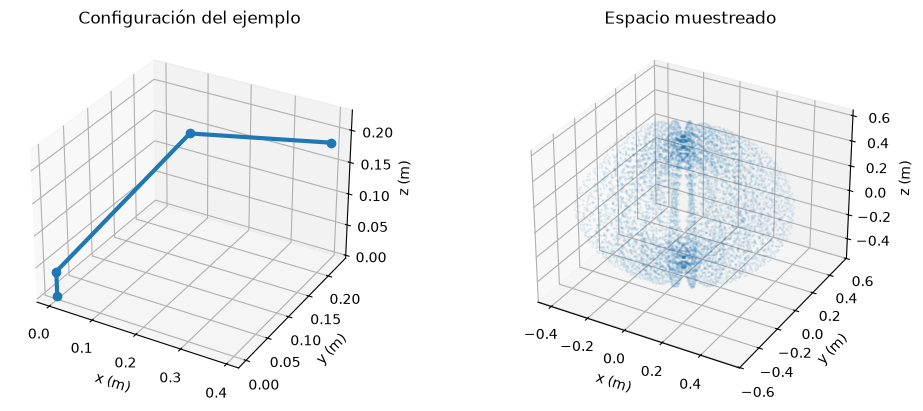

In [5]:
def joint_points(q):
    q1, q2, q3 = q
    shoulder = np.array([0, 0, l1])
    elbow = shoulder + l2 * np.array([
        np.cos(q1) * np.cos(q2), np.sin(q1) * np.cos(q2), np.sin(q2)
    ])
    return np.array([[0, 0, 0], shoulder, elbow, position(q)])

arm = joint_points(q)
positions = []
for q1 in np.deg2rad(np.linspace(-140, 140, 21)):
    for q2 in np.deg2rad(np.linspace(-120, 120, 21)):
        for q3 in np.deg2rad(np.linspace(-110, 110, 21)):
            positions.append(position([q1, q2, q3]))
positions = np.array(positions)
print("Posiciones muestreadas:", len(positions))

fig = plt.figure(figsize=(10, 4), layout="constrained")
ax = fig.add_subplot(121, projection="3d")
ax.plot(*arm.T, "o-", linewidth=3)
ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)", title="Configuración del ejemplo")
ax = fig.add_subplot(122, projection="3d")
ax.scatter(*positions.T, s=1, alpha=0.3)
ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)", title="Espacio muestreado")
plt.show()

## Lectura y ejercicio

La posición debe ser aproximadamente `[0.397078, 0.229253, 0.184733]` m. La coincidencia entre métodos comprueba la formulación, no la exactitud del robot real. La nube es un muestreo, no una prueba de alcanzabilidad de todos los puntos interiores.

Cambiar sólo `q1` debe girar la posición alrededor de z sin cambiar su altura. Con `q=[0,0,0]`, el efector debe quedar en `[0.53,0,0.04]` m. **Siguiente:** invertir este cálculo en [cinemática inversa](../inverse-kinematics/README.md).